# ISyE 6767 Lab 2 — Building the Project 2 dataset from raw ERCOT files

Project 2 trades the DART spread at ERCOT's North Hub:

$$S_{D,h} = P^{DA}_{D,h} - P^{RT}_{D,h}, \qquad y_{D,h} = \mathbb{1}\{S_{D,h} > 0\}.$$

All trades for day $D$ are decided at **9:00 AM on day $D-1$**. Anything you feed a model must have been
known at that moment. In this lab you build the hourly dataset yourself, starting from the files exactly as ERCOT
publishes them, and you learn one test that catches look-ahead in any feature you build later.

| Folder | ERCOT product | What one file is |
|---|---|---|
| `prices/` | NP4-180-ER, NP6-785-ER | one **year** of DA hub prices (hourly) / RT hub prices (15-minute), one sheet per month |
| `load_forecast/` | NP3-561-CD | 7-day load forecast by weather zone |
| `wind_forecast/` | NP4-732-CD | wind: actuals for the past 48 h + STWPF forecast for the next 7 days |
| `solar_forecast/` | NP4-737-CD | solar: same layout, STPPF forecast |
| `forecast_posting_times.csv` | ERCOT Public API | when each forecast file was posted |

Each forecast file is named after delivery day $D$ and is **the last one ERCOT posted before 9:00 on $D-1$**.
Delivery days: 2022-12-01 to 2025-12-31 (December 2022 is only there so that lags exist on 2023-01-01).

This lab is the data step of **Project 2** (`project2.pdf` on Canvas — read its *Decision time* and *Data Preparation and Cleaning*
sections first). What you build here, `ercot_hb_north_hourly.csv` and the `assert_no_lookahead` test, is where Part 1 of the project starts.

Work through the tasks in order. Each task ends with a **check cell**; when it runs without an `AssertionError`, move on.

In [2]:
%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
DATA = Path("lab2_data")      # change this if you unzipped somewhere else
HUB = "HB_NORTH"
TZ = "US/Central"             # ERCOT runs on Central Prevailing Time (CST in winter, CDT in summer)

## Task 0 — Look before you code

Open one sheet of each workbook. Reading Excel is slow (the RT workbooks have ~800k rows each), so look at a single sheet first.

1. How is time written in the DA workbook? In the RT workbook?
2. What does `Repeated Hour Flag` mean? Find a day where it is `Y`.
3. How many rows should a normal day have for one hub in each workbook? A day when clocks go forward? Back?

In [3]:
print(sorted(p.name for p in (DATA / "prices").glob("*.xlsx")))
da_nov = pd.read_excel(DATA / "prices" / "rpt.00013060.0000000000000000.DAMLZHBSPP_2023.xlsx", sheet_name="Nov")
da_nov.head()

['rpt.00013060.0000000000000000.DAMLZHBSPP_2022.xlsx', 'rpt.00013060.0000000000000000.DAMLZHBSPP_2023.xlsx', 'rpt.00013060.0000000000000000.DAMLZHBSPP_2024.xlsx', 'rpt.00013060.0000000000000000.DAMLZHBSPP_2025.xlsx', 'rpt.00013061.0000000000000000.RTMLZHBSPP_2022.xlsx', 'rpt.00013061.0000000000000000.RTMLZHBSPP_2023.xlsx', 'rpt.00013061.0000000000000000.RTMLZHBSPP_2024.xlsx', 'rpt.00013061.0000000000000000.RTMLZHBSPP_2025.xlsx']


,Delivery Date,Hour Ending,Repeated Hour Flag,Settlement Point,Settlement Point Price
0,11/01/2023,01:00,N,HB_BUSAVG,23.80
1,11/01/2023,01:00,N,HB_HOUSTON,23.06
2,11/01/2023,01:00,N,HB_HUBAVG,25.67
3,11/01/2023,01:00,N,HB_NORTH,21.78
4,11/01/2023,01:00,N,HB_PAN,17.92


In [4]:
da_nov[(da_nov["Settlement Point"] == HUB) & (da_nov["Delivery Date"] == "11/05/2023")].head(5)

,Delivery Date,Hour Ending,Repeated Hour Flag,Settlement Point,Settlement Point Price
1443,11/05/2023,01:00,N,HB_NORTH,19.92
1458,11/05/2023,02:00,N,HB_NORTH,21.68
1473,11/05/2023,02:00,Y,HB_NORTH,24.98
1488,11/05/2023,03:00,N,HB_NORTH,22.35
1503,11/05/2023,04:00,N,HB_NORTH,23.01


### Why time is the hard part

ERCOT labels an hour by its **hour ending** in local time: HE 1 is 00:00–01:00, HE 24 is 23:00–24:00.

* **Fall back** (first Sunday of November): 01:00–02:00 happens twice. ERCOT publishes HE 2 twice;
  the second copy has `Repeated Hour Flag = Y` (prices) or `DSTFlag = Y` (forecasts). That day has 25 hours.
* **Spring forward** (second Sunday of March): 02:00–03:00 never happens. That day has 23 hours.

If you key your data on "date + hour" you will merge the wrong rows on those days. We give every hour an
unambiguous key instead: the **start of the hour in UTC**. Hour ending $h$ starts at local time $h-1$;
the repeated copy is standard time, the first copy daylight time.

In [5]:
def hour_start_utc(delivery_date, hour_ending, repeated):
    # Local start = date + (HE - 1) hours. `ambiguous` tells pandas which copy of the repeated hour
    # we mean (True = daylight time = first copy). A label that cannot exist becomes NaT.
    start = pd.to_datetime(delivery_date) + pd.to_timedelta(np.asarray(hour_ending) - 1, unit="h")
    return (pd.DatetimeIndex(start)
            .tz_localize(TZ, ambiguous=~np.asarray(repeated, dtype=bool), nonexistent="NaT")
            .tz_convert("UTC"))


hour_start_utc(["2023-11-05"] * 3, [2, 2, 3], [False, True, False])

DatetimeIndex(['2023-11-05 06:00:00+00:00', '2023-11-05 07:00:00+00:00', '2023-11-05 08:00:00+00:00'], dtype='datetime64[us, UTC]', freq=None)

## Task 1 — Day-ahead prices

Write `read_workbooks(folder, pattern)` that reads **every sheet** of every matching workbook and stacks them
(`pd.read_excel(f, sheet_name=None)` returns a dict of DataFrames), and `load_dam(folder)` that keeps `HB_NORTH` and returns

`delivery_date, hour_ending (int), repeated (bool), da_price, interval_start_utc`.

*Hint:* `"Hour Ending"` looks like `"01:00"`.

In [6]:

def read_workbooks(folder, pattern):
    frames = []

    # Read every matching Excel workbook
    for file in sorted(Path(folder).glob(pattern)):
        sheets = pd.read_excel(file, sheet_name=None)

        # Combine all monthly sheets
        for sheet in sheets.values():
            frames.append(sheet)

    return pd.concat(frames, ignore_index=True)


def load_dam(folder):
    raw = read_workbooks(folder, "*DAMLZHBSPP_*.xlsx")

    # Keep only HB_NORTH prices
    dam = raw.loc[raw["Settlement Point"] == HUB].copy()

    # Convert delivery dates
    dam["delivery_date"] = pd.to_datetime(
        dam["Delivery Date"], format="%m/%d/%Y"
    )

    # Convert "01:00" to integer 1
    dam["hour_ending"] = (
        dam["Hour Ending"].astype(str).str.split(":").str[0].astype(int)
    )

    # Identify the second occurrence of repeated hours
    dam["repeated"] = dam["Repeated Hour Flag"].eq("Y")

    # Extract day-ahead settlement prices
    dam["da_price"] = dam["Settlement Point Price"]

    # Build an unambiguous UTC key
    dam["interval_start_utc"] = hour_start_utc(
        dam["delivery_date"],
        dam["hour_ending"],
        dam["repeated"]
    )

    columns = [
        "delivery_date",
        "hour_ending",
        "repeated",
        "da_price",
        "interval_start_utc"
    ]

    return (
        dam[columns]
        .sort_values("interval_start_utc")
        .reset_index(drop=True)
    )


dam = load_dam(DATA / "prices")
dam.head()




,delivery_date,hour_ending,repeated,da_price,interval_start_utc
0,2022-01-01,1,False,33.41,2022-01-01 06:00:00+00:00
1,2022-01-01,2,False,25.22,2022-01-01 07:00:00+00:00
2,2022-01-01,3,False,22.91,2022-01-01 08:00:00+00:00
3,2022-01-01,4,False,18.41,2022-01-01 09:00:00+00:00
4,2022-01-01,5,False,12.19,2022-01-01 10:00:00+00:00


In [7]:
# Check 1
assert len(dam) == 35064, len(dam)                                     # 2022-2025
assert dam.groupby("delivery_date").size().value_counts().to_dict() == {24: 1453, 23: 4, 25: 4}
assert dam.interval_start_utc.notna().all() and not dam.interval_start_utc.duplicated().any()
s = dam.set_index("interval_start_utc").da_price
assert s[pd.Timestamp("2023-11-05 06:00", tz="UTC")] == 21.68    # HE 2, first copy (CDT)
assert s[pd.Timestamp("2023-11-05 07:00", tz="UTC")] == 24.98      # HE 2, repeated copy (CST)
print("Task 1 OK")

Task 1 OK


## Task 2 — Real-time prices: 15 minutes → 1 hour

The RT workbook has one row per hub per **15-minute interval** (`Delivery Hour`, `Delivery Interval` 1–4,
`Repeated Hour Flag`). The hourly RT price is the average of the four intervals in the hour.

Write `load_rt(folder)`: keep `HB_NORTH`, group by `(delivery date, hour, repeated flag)`, and compute
`rt_price` (mean) and `rt_n_intervals` (count). Return `interval_start_utc, rt_price, rt_n_intervals`.

Reading four RT workbooks takes a couple of minutes, so the cell saves the result and reuses it next time.

In [8]:

def load_rt(folder):
    raw = read_workbooks(folder, "*RTMLZHBSPP_*.xlsx")

    # Keep only HB_NORTH
    raw = raw.loc[raw["Settlement Point Name"] == HUB].copy()

    # Aggregate four 15-minute prices into one hourly price
    rt = (
        raw.groupby(
            ["Delivery Date", "Delivery Hour", "Repeated Hour Flag"],
            as_index=False
        )
        .agg(
            rt_price=("Settlement Point Price", "mean"),
            rt_n_intervals=("Delivery Interval", "count")
        )
    )

    # Convert delivery dates and hours
    rt["delivery_date"] = pd.to_datetime(
        rt["Delivery Date"], format="%m/%d/%Y"
    )

    rt["hour_ending"] = rt["Delivery Hour"].astype(int)

    rt["repeated"] = rt["Repeated Hour Flag"].eq("Y")

    # Convert to unique UTC timestamps
    rt["interval_start_utc"] = hour_start_utc(
        rt["delivery_date"],
        rt["hour_ending"],
        rt["repeated"]
    )

    return (
        rt[["interval_start_utc", "rt_price", "rt_n_intervals"]]
        .sort_values("interval_start_utc")
        .reset_index(drop=True)
    )


cache = Path("rt_hourly_cache.pkl")

if cache.exists():
    rt = pd.read_pickle(cache)
else:
    rt = load_rt(DATA / "prices")
    rt.to_pickle(cache)

rt.head()


,interval_start_utc,rt_price,rt_n_intervals
0,2022-01-01 06:00:00+00:00,64.3600,4
1,2022-01-01 07:00:00+00:00,32.4475,4
2,2022-01-01 08:00:00+00:00,25.5400,4
3,2022-01-01 09:00:00+00:00,22.4175,4
4,2022-01-01 10:00:00+00:00,15.9475,4


In [9]:
# Check 2
assert len(rt) == 35064 and (rt.rt_n_intervals == 4).all()
assert set(rt.interval_start_utc) == set(dam.interval_start_utc)
r = rt.set_index("interval_start_utc").rt_price
assert abs(r[pd.Timestamp("2023-11-05 06:00", tz="UTC")] - 22.0125) < 1e-9
assert abs(r[pd.Timestamp("2023-11-05 07:00", tz="UTC")] - 23.8775) < 1e-9
print("Task 2 OK")

Task 2 OK


**Question 2.** Why do we average the 15-minute prices instead of taking the last interval of the hour?
(Think about how a 1 MWh position held over the hour is settled.)

## Task 3 — Forecasts known at 9:00 on $D-1$

**3a.** Use `forecast_posting_times.csv` to check that every forecast file was posted before 9:00 on $D-1$.

Each file still contains far more than you may use:

* rows for other days (the past 48 hours and the next 7 days) — keep only rows for day $D$;
* in the wind/solar files, **actual** generation (`*_GEN`, `*_HSL`) for past hours — never a feature;
* in the load file, one column per weather zone plus `SystemTotal`. Project 2 asks for the system total and the `North` zone.

In [10]:

posted = pd.read_csv(
    DATA / "forecast_posting_times.csv",
    parse_dates=["delivery_date", "posted_central"]
)

# Decision deadline: 9 AM on the day before delivery
posted["decision_time"] = (
    posted["delivery_date"]
    - pd.Timedelta(days=1)
    + pd.Timedelta(hours=9)
)

# Every forecast must have been published before the deadline
assert (posted["posted_central"] < posted["decision_time"]).all()

print("Forecast files checked:", len(posted))
print("Late forecasts:", (posted["posted_central"] >= posted["decision_time"]).sum())
print("Task 3a OK")


Forecast files checked: 3381
Late forecasts: 0
Task 3a OK


**3b.** Write `load_forecast(folder, date_col, he_col, columns)` where `columns` maps source column → output name.
For each file keep the rows of the delivery day in its file name, parse the hour (`"1:00"` in the load file, `"01"` in wind/solar),
use `DSTFlag == "Y"` as the repeated flag, and return `interval_start_utc` plus the renamed columns.
Drop (and print) rows whose local hour cannot exist.

| output | folder | source column |
|---|---|---|
| `load_fcst_system_mw` | `load_forecast` | `SystemTotal` |
| `load_fcst_north_mw` | `load_forecast` | `North` |
| `wind_fcst_mw` | `wind_forecast` | `STWPF_SYSTEM_WIDE` |
| `solar_fcst_mw` | `solar_forecast` | `STPPF_SYSTEM_WIDE` |

In [11]:

def load_forecast(folder, date_col, he_col, columns):
    out = []

    for f in sorted(Path(folder).glob("2*.csv")):
        # Each filename identifies its delivery day
        target = pd.to_datetime(f.stem, format="%Y%m%d")

        raw = pd.read_csv(f, dtype={he_col: str})

        # Convert dates
        raw["delivery_date"] = pd.to_datetime(
            raw[date_col], format="%m/%d/%Y"
        )

        # Retain only the target delivery day
        raw = raw.loc[raw["delivery_date"] == target].copy()

        # Parse hour ending (handles both "1:00" and "01")
        raw["hour_ending"] = (
            raw[he_col].str.split(":").str[0].astype(int)
        )

        # Identify repeated daylight-saving hours
        raw["repeated"] = raw["DSTFlag"].eq("Y")

        # Keep only the requested forecast columns
        raw = raw.rename(columns=columns)

        out.append(
            raw[
                [
                    "delivery_date",
                    "hour_ending",
                    "repeated",
                    *columns.values()
                ]
            ]
        )

    # Combine forecasts from every delivery day
    df = pd.concat(out, ignore_index=True)

    # Convert to unique UTC timestamps
    df["interval_start_utc"] = hour_start_utc(
        df.delivery_date,
        df.hour_ending,
        df.repeated
    )

    # Identify impossible local hours
    bad = df[df.interval_start_utc.isna()]

    print(
        list(columns.values()),
        "impossible local hours dropped:",
        bad[["delivery_date", "hour_ending"]].values.tolist()
    )

    return df.dropna(
        subset=["interval_start_utc"]
    )[["interval_start_utc", *columns.values()]]


# Load forecast
load = load_forecast(
    DATA / "load_forecast",
    "DeliveryDate",
    "HourEnding",
    {
        "SystemTotal": "load_fcst_system_mw",
        "North": "load_fcst_north_mw"
    }
)

# Wind forecast
wind = load_forecast(
    DATA / "wind_forecast",
    "DELIVERY_DATE",
    "HOUR_ENDING",
    {
        "STWPF_SYSTEM_WIDE": "wind_fcst_mw"
    }
)

# Solar forecast
solar = load_forecast(
    DATA / "solar_forecast",
    "DELIVERY_DATE",
    "HOUR_ENDING",
    {
        "STPPF_SYSTEM_WIDE": "solar_fcst_mw"
    }
)


['load_fcst_system_mw', 'load_fcst_north_mw'] impossible local hours dropped: []
['wind_fcst_mw'] impossible local hours dropped: []
['solar_fcst_mw'] impossible local hours dropped: [[Timestamp('2023-03-12 00:00:00'), 3], [Timestamp('2024-03-10 00:00:00'), 3], [Timestamp('2025-03-09 00:00:00'), 3]]


In [12]:
# Check 3
fc_hours = set(dam.loc[dam.delivery_date >= "2022-12-01", "interval_start_utc"])
for part in (load, wind, solar):
    assert not part.interval_start_utc.duplicated().any()
    missing = sorted(fc_hours - set(part.interval_start_utc))
    print(part.columns[-1], "hours missing:", [str(t.tz_convert(TZ)) for t in missing])
assert len(load) == 27048 and len(wind) == 27048 and len(solar) == 27045
print("Task 3 OK")

load_fcst_north_mw hours missing: []
wind_fcst_mw hours missing: []
solar_fcst_mw hours missing: ['2023-03-12 01:00:00-06:00', '2024-03-10 01:00:00-06:00', '2025-03-09 01:00:00-06:00']
Task 3 OK


**Question 3.** Look at the missing hours printed above. Some come from ERCOT labelling the spring-forward gap
differently in different reports. Which hours are they, and what value is defensible for each?
Why is it wrong to use `SYSTEM_WIDE_GEN` from the wind file as a feature, even though it sits in the same file as the forecast?

## Task 4 — One table

Keep delivery days 2022-12-01 to 2025-12-31 from `dam` (it defines which hours exist), left-merge `rt`, `load`, `wind`, `solar`
on `interval_start_utc`, decide what to do with the missing forecast hours from Task 3, and compute `spread` and `y`.
Add `interval_start_local` and save the result as `ercot_hb_north_hourly.csv`.

In [13]:

# Task 4: Merge all datasets into one hourly table

# Keep December 2022 onward
df = dam.loc[
    dam["delivery_date"] >= "2022-12-01"
].copy()

# Merge real-time prices and forecasts on the UTC key
for part in [rt, load, wind, solar]:
    df = df.merge(
        part,
        on="interval_start_utc",
        how="left",
        validate="one_to_one"
    )

# Sort chronologically
df = df.sort_values(
    "interval_start_utc"
).reset_index(drop=True)

# Identify missing solar forecasts
missing_solar = df["solar_fcst_mw"].isna()

print("Missing solar values:", missing_solar.sum())
print(
    df.loc[
        missing_solar,
        ["delivery_date", "hour_ending", "interval_start_utc"]
    ]
)

# Verify exactly the three known DST-related missing hours
expected_dates = {
    "2023-03-12",
    "2024-03-10",
    "2025-03-09"
}

assert missing_solar.sum() == 3

assert set(
    df.loc[missing_solar, "delivery_date"].dt.strftime("%Y-%m-%d")
) == expected_dates

assert (df.loc[missing_solar, "hour_ending"] == 2).all()

# Fill these three nighttime solar forecasts with zero
df.loc[missing_solar, "solar_fcst_mw"] = 0.0

# Calculate the DART spread and classification label
df["spread"] = df["da_price"] - df["rt_price"]
df["y"] = (df["spread"] > 0).astype(int)

# Add local Central time for interpretation
df["interval_start_local"] = (
    df["interval_start_utc"].dt.tz_convert(TZ)
)

# Check for remaining missing data
assert df.isna().sum().sum() == 0

# Save the cleaned hourly dataset
df.to_csv("ercot_hb_north_hourly.csv", index=False)

print("Dataset shape:", df.shape)
print("Task 4 dataset saved successfully")


Missing solar values: 3
      delivery_date  hour_ending        interval_start_utc
2425     2023-03-12            2 2023-03-12 07:00:00+00:00
11161    2024-03-10            2 2024-03-10 07:00:00+00:00
19897    2025-03-09            2 2025-03-09 07:00:00+00:00
Dataset shape: (27048, 14)
Task 4 dataset saved successfully


In [14]:
# Check 4
assert df.shape == (27048, 14), df.shape
assert df.isna().sum().sum() == 0, df.isna().sum()[df.isna().sum() > 0]
assert df.interval_start_utc.is_monotonic_increasing
print(df.groupby(df.delivery_date.dt.year).agg(hours=("y", "size"), share_positive=("y", "mean")).round(3))
print("Task 4 OK")

               hours  share_positive
delivery_date                       
2022             744           0.655
2023            8760           0.635
2024            8784           0.544
2025            8760           0.625
Task 4 OK


## Task 5 — Lagged prices without look-ahead

At 9:00 on $D-1$ the DA prices of day $D$ are unknown, and RT prices of $D-1$ are only partly known.
So every price-based feature for day $D$ must use **day $D-2$ or earlier**.

Two classic mistakes:

* `df.spread.shift(24)` — 24 rows back is day $D-1$, not $D-2$; and on a 23- or 25-hour day it is not even the same hour.
* `df.spread.rolling(24 * 7).mean()` — the window ends at the current hour, i.e. it contains the very spread you want to predict.

A simple test catches both: **overwrite every price from day $D-1$ on with garbage, recompute the feature, and check that
the feature for day $D$ did not change.** If it changed, the feature looked at something it could not have known.

In [15]:
def assert_no_lookahead(feature_fn, df, days=("2023-07-15", "2024-03-10", "2025-11-03")):
    # feature_fn(df) -> DataFrame (same index as df) of features; must not use prices of D-1 or later for day D.
    clean = feature_fn(df)
    for d in pd.to_datetime(list(days)):
        poisoned = df.copy()
        late = poisoned.delivery_date >= d - pd.Timedelta(days=1)
        rng = np.random.default_rng(0)
        for c in ["da_price", "rt_price", "spread"]:
            poisoned.loc[late, c] = rng.normal(1e4, 1e3, late.sum())
        poisoned["y"] = (poisoned.spread > 0).astype(int)
        dirty = feature_fn(poisoned)
        rows = df.delivery_date == d
        if not clean[rows].equals(dirty[rows]):
            bad = [c for c in clean if not clean.loc[rows, c].equals(dirty.loc[rows, c])]
            raise AssertionError(f"look-ahead on {d.date()} in {bad}")
    print("no look-ahead in", list(clean.columns))

In [16]:
def wrong_features(df):
    return pd.DataFrame({"spread_shift24": df.spread.shift(24),
                         "spread_roll7d": df.spread.rolling(24 * 7).mean()}, index=df.index)


try:
    assert_no_lookahead(wrong_features, df)
except AssertionError as e:
    print("caught:", e)

caught: look-ahead on 2023-07-15 in ['spread_shift24', 'spread_roll7d']


**5.** Write `lag_features(df)` returning `spread_lag2`: the spread in the **same local hour ending** on day $D-2$.
Do it with a merge on `(delivery_date, hour_ending)`, not with `shift`: take the first copy of each hour
(`~repeated`), move its date forward by two days, and merge it back. It must pass `assert_no_lookahead`.

The other price features in Project 2 (the $D-7$ lag, rolling same-hour means/std/fraction positive ending at $D-2$) are
yours to build in the project — run every one of them through `assert_no_lookahead`.

In [17]:

def lag_features(df):
    # Use the first copy of each hour on repeated-hour days
    history = df.loc[
        ~df["repeated"],
        ["delivery_date", "hour_ending", "spread"]
    ].copy()

    # A spread observed on day D-2 becomes available
    # as a feature for delivery day D
    history["delivery_date"] += pd.Timedelta(days=2)

    # Rename the historical spread
    history = history.rename(
        columns={"spread": "spread_lag2"}
    )

    # Match each target hour to the same hour on D-2
    merged = df[
        ["delivery_date", "hour_ending"]
    ].merge(
        history,
        on=["delivery_date", "hour_ending"],
        how="left",
        sort=False,
        validate="many_to_one"
    )

    # Preserve the original DataFrame index
    return pd.DataFrame(
        {"spread_lag2": merged["spread_lag2"].to_numpy()},
        index=df.index
    )


feat = lag_features(df)

# Verify that future prices cannot affect the lag
assert_no_lookahead(lag_features, df)


no look-ahead in ['spread_lag2']


In [18]:
# Check 5
lag = feat.spread_lag2
i = df.index[(df.interval_start_utc == pd.Timestamp("2024-07-03 20:00", tz="UTC"))][0]
j = df.index[(df.interval_start_utc == pd.Timestamp("2024-07-01 20:00", tz="UTC"))][0]
assert lag[i] == df.spread[j]
print("rows without a D-2 value:", lag.isna().sum(), "(first two days + hours that did not exist two days earlier)")
print("Task 5 OK")

rows without a D-2 value: 51 (first two days + hours that did not exist two days earlier)
Task 5 OK


## Task 6 — Sanity checks you should always run

1. Class balance per year (2023 / 2024 / 2025): this is the accuracy of **Always INC** in Project 2.
2. Plot DA, RT and the spread over time. Find the five largest $|S|$ hours. Errors or real events?
3. How many hours have negative DA or RT prices? Should they be removed?
4. Average spread and share positive by hour of day. Does HB North have a persistent DA premium?

CLASS BALANCE BY YEAR


,hours,share_positive,always_inc_accuracy,always_dec_accuracy
delivery_date,,,,
2023,8760,0.635,0.635,0.365
2024,8784,0.544,0.544,0.456
2025,8760,0.625,0.625,0.375


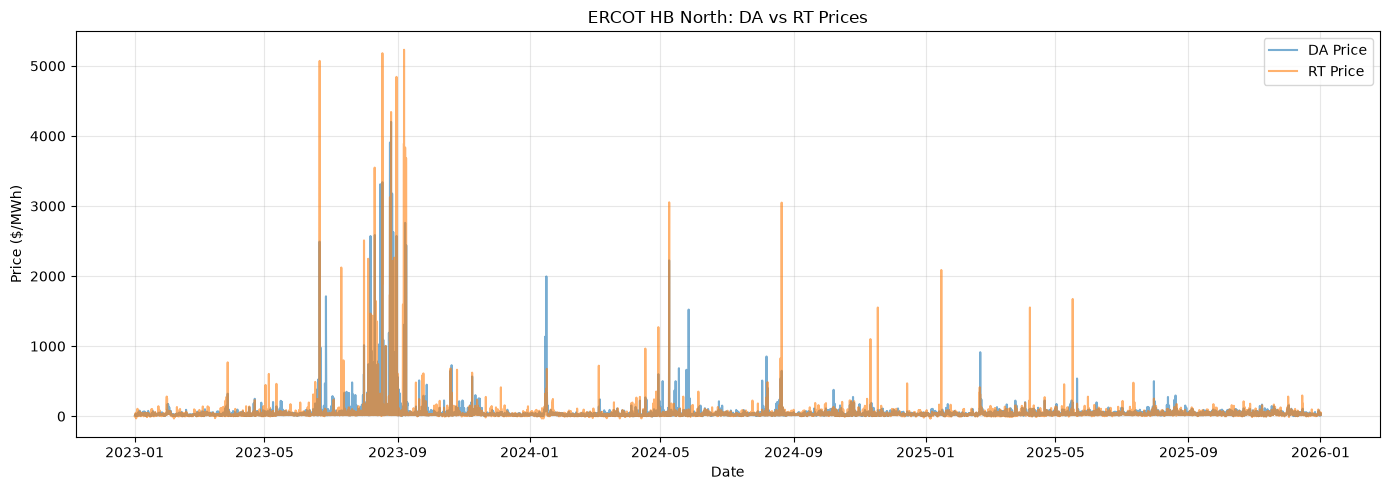

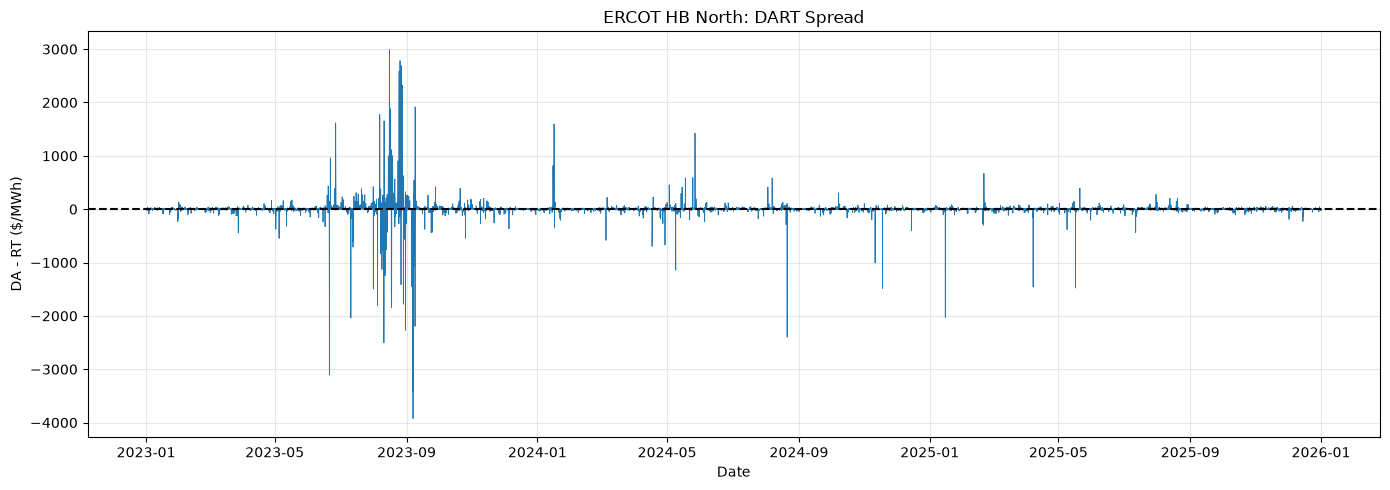


FIVE LARGEST ABSOLUTE SPREADS


,interval_start_local,da_price,rt_price,spread,abs_spread
6714,2023-09-06 19:00:00-05:00,1306.35,5229.8400,-3923.4900,3923.4900
6711,2023-09-06 16:00:00-05:00,467.10,3893.2425,-3426.1425,3426.1425
6710,2023-09-06 15:00:00-05:00,311.35,3536.4150,-3225.0650,3225.0650
4842,2023-06-20 19:00:00-05:00,1964.91,5070.9300,-3106.0200,3106.0200
6186,2023-08-15 19:00:00-05:00,3310.39,322.4900,2987.9000,2987.9000



NEGATIVE PRICE ANALYSIS
Negative DA hours: 6
Negative RT hours: 538
Hours with either price negative: 541

HOURLY SPREAD STATISTICS


,avg_spread,share_positive
hour_ending,,
1,0.485,0.569
2,-0.012,0.517
3,-0.011,0.501
4,-0.048,0.510
5,-0.052,0.524
6,0.158,0.544
7,0.076,0.531
8,1.435,0.565
9,2.449,0.594


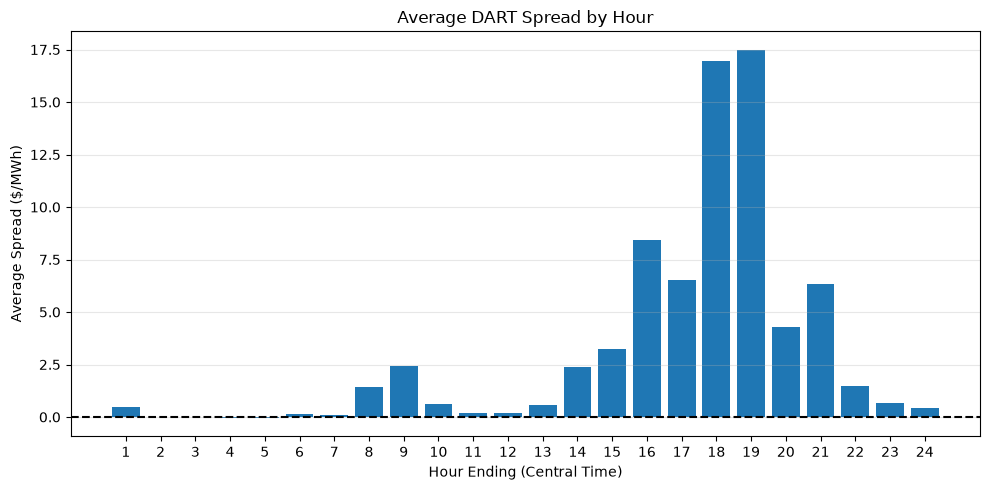

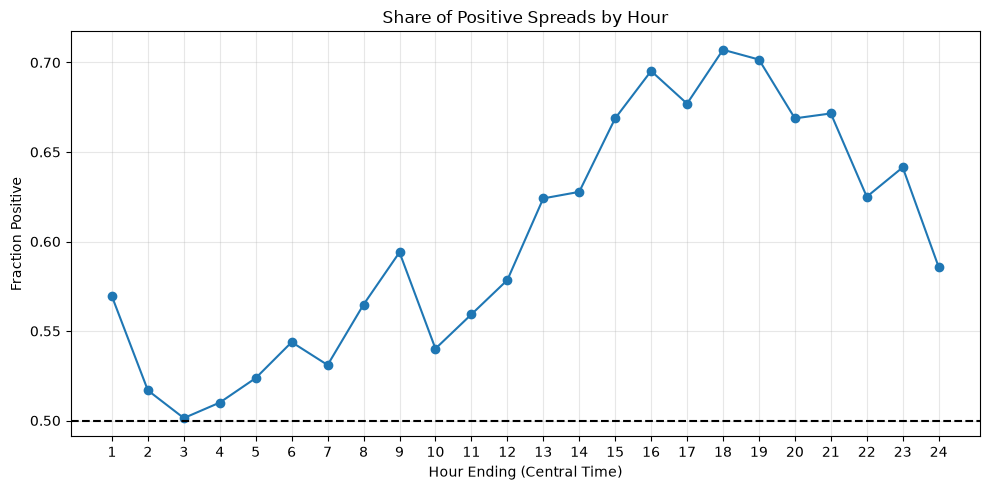


Task 6 completed


In [19]:

# Task 6: Data sanity checks

# --------------------------------------------------
# 1. Class balance by year
# --------------------------------------------------

analysis = df[df["delivery_date"].dt.year >= 2023].copy()

yearly = (
    analysis.groupby(analysis["delivery_date"].dt.year)
    .agg(
        hours=("y", "size"),
        share_positive=("y", "mean")
    )
)

yearly["always_inc_accuracy"] = yearly["share_positive"]
yearly["always_dec_accuracy"] = 1 - yearly["share_positive"]

print("CLASS BALANCE BY YEAR")
display(yearly.round(3))


# --------------------------------------------------
# 2. DA, RT and spread over time
# --------------------------------------------------

plt.figure(figsize=(14, 5))

plt.plot(analysis["interval_start_utc"],
         analysis["da_price"],
         label="DA Price", alpha=0.6)

plt.plot(analysis["interval_start_utc"],
         analysis["rt_price"],
         label="RT Price", alpha=0.6)

plt.title("ERCOT HB North: DA vs RT Prices")
plt.xlabel("Date")
plt.ylabel("Price ($/MWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


plt.figure(figsize=(14, 5))

plt.plot(analysis["interval_start_utc"],
         analysis["spread"], linewidth=0.6)

plt.axhline(0, color="black", linestyle="--")

plt.title("ERCOT HB North: DART Spread")
plt.xlabel("Date")
plt.ylabel("DA - RT ($/MWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Five largest absolute spreads
extreme = (
    analysis.assign(abs_spread=analysis["spread"].abs())
    .nlargest(5, "abs_spread")
)

print("\nFIVE LARGEST ABSOLUTE SPREADS")
display(
    extreme[
        ["interval_start_local", "da_price",
         "rt_price", "spread", "abs_spread"]
    ]
)


# --------------------------------------------------
# 3. Negative prices
# --------------------------------------------------

negative_da = (analysis["da_price"] < 0).sum()
negative_rt = (analysis["rt_price"] < 0).sum()
negative_either = (
    (analysis["da_price"] < 0) |
    (analysis["rt_price"] < 0)
).sum()

print("\nNEGATIVE PRICE ANALYSIS")
print("Negative DA hours:", negative_da)
print("Negative RT hours:", negative_rt)
print("Hours with either price negative:", negative_either)


# --------------------------------------------------
# 4. Hour-of-day analysis
# --------------------------------------------------

hourly = (
    analysis.groupby("hour_ending")
    .agg(
        avg_spread=("spread", "mean"),
        share_positive=("y", "mean")
    )
)

print("\nHOURLY SPREAD STATISTICS")
display(hourly.round(3))


# Plot average spread by hour
plt.figure(figsize=(10, 5))

plt.bar(hourly.index, hourly["avg_spread"])

plt.axhline(0, color="black", linestyle="--")

plt.title("Average DART Spread by Hour")
plt.xlabel("Hour Ending (Central Time)")
plt.ylabel("Average Spread ($/MWh)")
plt.xticks(range(1, 25))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Plot share of positive spreads
plt.figure(figsize=(10, 5))

plt.plot(hourly.index,
         hourly["share_positive"],
         marker="o")

plt.axhline(0.5, color="black", linestyle="--")

plt.title("Share of Positive Spreads by Hour")
plt.xlabel("Hour Ending (Central Time)")
plt.ylabel("Fraction Positive")
plt.xticks(range(1, 25))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTask 6 completed")


## What to keep for Project 2

* Your functions (notebook or `.py` module): Project 2 must regenerate every result from the raw files.
* `ercot_hb_north_hourly.csv`. `da_price`, `rt_price`, `spread` and `y` of day $D$ are **outcomes**: labels and P&L only.
  Price features must come from $D-2$ or earlier, and every feature you build should pass `assert_no_lookahead`.